# 01. 데이터 구성과 시간·공정 품질

원본은 읽기 전용이며, 전체 센서 파일은 최대 200,000행씩 필요한 열만 읽습니다. 전체 원본을 하나의 Pandas DataFrame으로 결합하지 않습니다. 소형 fault 이력만 전체 읽기합니다. 입력 경로·크기·수정 시각과 코드 해시가 같은 경우 청크 집계 캐시를 재사용합니다.

**범위:** train 20개는 주요 센서 6개와 공정·시간을 집계하고, test 5개는 구조·시간·공정만 확인합니다. 테스트 센서 분포로 특징이나 임계값을 선택하지 않습니다. 모델 학습은 없습니다.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018", sys.executable
assert sys.version_info[:2]==(3,11), sys.version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.eda_common import DATA, OUT, SENSORS, FAULTS, SOURCE_URL, overview, read_json, load_faults, snapshot
from src.eda_detail import representative, audit_time_keys, audit_tagged_ttf, horizon_labels
from src import eda_plots as plots
plots.setup()
pd.set_option("display.max_columns",30)
pd.set_option("display.max_rows",80)
print("실행 Python:",sys.executable)
print("Python 버전:",sys.version.split()[0])

실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
Python 버전: 3.11.18


## 이전 단계 확인과 실제 파일 구조

`src/inspect_data.py`, 초기 `inspection.json` 및 파일별 헤더를 다시 확인합니다. 초기 5행의 dtype 추정과 이번 전체 청크의 엄격한 수치 파싱을 구분합니다.

In [2]:
initial_path=ROOT/"reports/local/inspection.json"
initial=pd.read_json(initial_path,typ="series")
print("초기 점검:",initial["file_count"],"개 파일 / 대표",initial["sample"]["rows_read"],"행")
print((ROOT/"src/inspect_data.py").read_text(encoding="utf-8")[:350])
result=overview()
schemas=pd.DataFrame(result["schemas"])
schemas["컬럼 수"]=schemas["columns"].map(len)
display(schemas[["path","bytes","컬럼 수"]])
for kind, sub in schemas.groupby(schemas.path.str.contains("train_faults").map({True:"fault",False:"기타"})):
    print(kind,"파일 수:",len(sub))
sensor_schema=initial["sample"]["columns"]
checks=[]
for row in result["schemas"]:
    kind="fault" if "train_faults/" in row["path"] else "ttf" if "train_ttf/" in row["path"] else "sensor"
    expected=["time","fault_name","Tool"] if kind=="fault" else ["time"]+["TTF_"+f for f in FAULTS] if kind=="ttf" else sensor_schema
    checks.append({"파일":row["path"],"유형":kind,"헤더 일치":row["columns"]==expected})
display(pd.DataFrame(checks).groupby("유형")["헤더 일치"].agg(["count","all"]))
display(pd.DataFrame({"컬럼":sensor_schema,"초기 5행 dtype":[initial["sample"]["dtypes_inferred_from_five_rows"][c] for c in sensor_schema]}))

초기 점검: 65 개 파일 / 대표 5 행
"""Read-only file inventory; inspect at most five rows of ONE sensor CSV.

Other representative CSVs are opened only to read their header. No training,
full-file scan, extraction, upload, or modification of source files occurs.
"""
from __future__ import annotations

import argparse
from collections import Counter
import csv
import json
from pathli
검증된 입력/코드 메타데이터와 일치하는 로컬 집계 캐시 사용


,path,bytes,컬럼 수
0,test/01_M02_DC_test.csv,612811738,24
1,test/02_M02_DC_test.csv,496104815,24
2,test/03_M01_DC_test.csv,405758865,24
3,test/04_M01_DC_test.csv,601247123,24
4,test/06_M01_DC_test.csv,451894228,24
5,train/01_M01_DC_train.csv,1107918027,24
6,train/01_M02_DC_train.csv,1834454670,24
7,train/02_M01_DC_train.csv,1012645089,24
8,train/02_M02_DC_train.csv,1487585817,24
9,train/03_M01_DC_train.csv,1210432632,24


fault 파일 수: 20
기타 파일 수: 45


,count,all
유형,,
fault,20,True
sensor,25,True
ttf,20,True


,컬럼,초기 5행 dtype
0,time,int64
1,Tool,str
2,stage,int64
3,Lot,int64
4,runnum,int64
5,recipe,int64
6,recipe_step,float64
7,IONGAUGEPRESSURE,float64
8,ETCHBEAMVOLTAGE,float64
9,ETCHBEAMCURRENT,float64


## Tool별 관측 수, 측정 범위와 실제 간격

`time`은 절대 날짜로 변환하지 않습니다. 원시 좌표의 최소·최대와 차이를 제시합니다. 간격 집계는 원본 순서와 청크 경계를 유지하고 Tool별로 계산합니다. 양의 간격의 최빈값과 0 간격(동시각 행), 역전, 긴 공백을 분리합니다.

,split,file,Tool,관측 행 수,시작 원시시각,종료 원시시각,측정 범위 원시단위,양의 간격 최빈값,동시각 인접행,시간 역전,null_time,최빈간격 초과 수
0,train,01_M01_DC_train.csv,01M01,3124704,3283106.0,43037336.0,39754230.0,4.0,5273,0,0,42075
1,train,01_M02_DC_train.csv,01M02,5110542,3283834.0,39789840.0,36506006.0,4.0,7455,0,0,39043
2,train,02_M01_DC_train.csv,02M01,2865625,3283718.0,32494970.0,29211252.0,4.0,1570,0,0,45358
3,train,02_M02_DC_train.csv,02M02,4143973,3283198.0,36485084.0,33201886.0,4.0,2258,0,0,65296
4,train,03_M01_DC_train.csv,03M01,3432217,3286668.0,41658086.0,38371418.0,4.0,1026,0,0,33325
5,train,03_M02_DC_train.csv,03M02,5060498,3284714.0,44029722.0,40745008.0,4.0,1168,0,0,47557
6,train,04_M01_DC_train.csv,04M01,5097901,3283122.0,43627882.0,40344760.0,4.0,1638,0,0,43687
7,train,04_M02_DC_train.csv,04M02,4450348,3997500.0,42499202.0,38501702.0,4.0,1208,0,0,24009
8,train,05_M01_DC_train.csv,05M01,4779554,3280856.0,42635582.0,39354726.0,4.0,20236,0,0,76743
9,train,05_M02_DC_train.csv,05M02,1907102,3286308.0,43254162.0,39967854.0,4.0,9473,0,0,34829


,split,delta_raw,count
2400,train,4.0,80076715
2,test,4.0,7066795
2399,train,2.0,905154
2401,train,6.0,751170
2398,train,0.0,117533
1,test,2.0,52284
3,test,6.0,44734
2474,train,152.0,22353
2470,train,144.0,15357
2472,train,148.0,15274


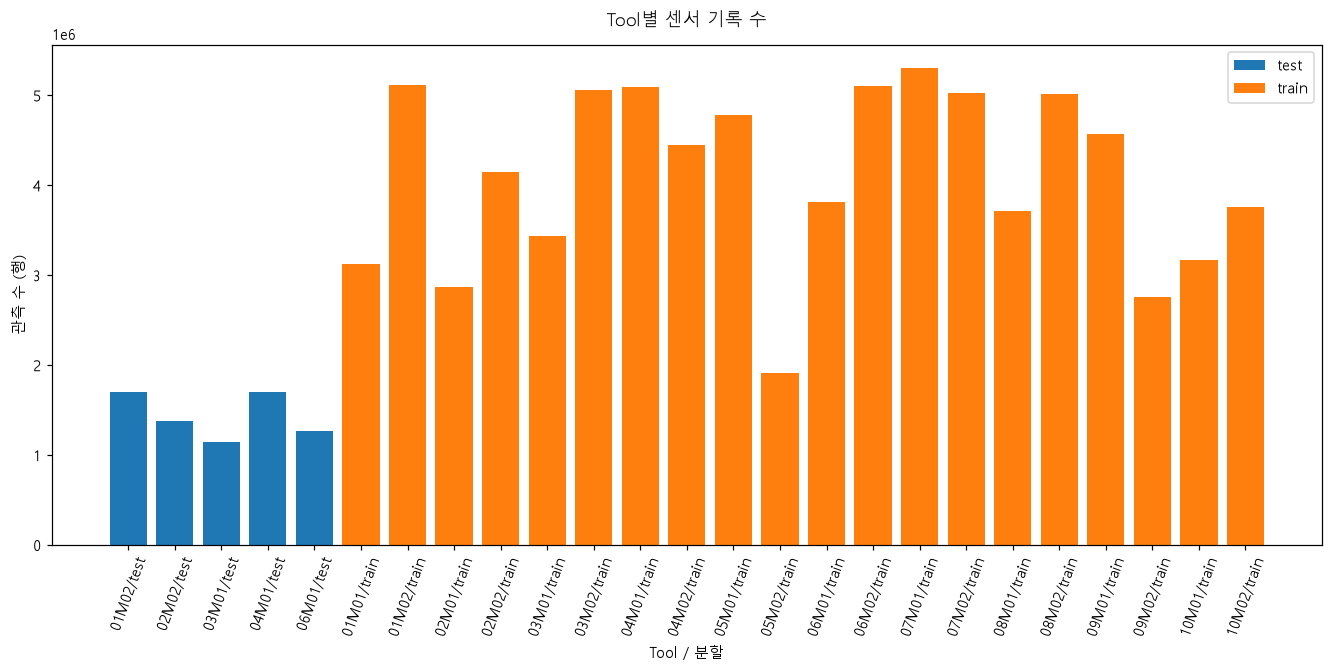

,min_time,max_time,train_test_경계간격
Tool,,,
01M02,39789844.0,39789840.0,4.0
02M02,36485088.0,36485084.0,4.0
03M01,41658090.0,41658086.0,4.0
04M01,43627886.0,43627882.0,4.0
06M01,41751466.0,41751462.0,4.0


학습 센서는 **82,189,440행**, 테스트 센서는 **7,198,948행**입니다. 모든 파일의 양의 간격 최빈값은 [np.float64(4.0)] 원시시간 단위입니다. 학습 데이터에 동시각 인접 기록 **117,533개**가 있으므로 `(Tool,time)`은 고유 행 키가 아닙니다. 테스트는 기존 학습 장비 5개의 후속 구간이며 장비 독립 평가로 해석할 수 없습니다.

In [3]:
tools=pd.DataFrame(result["tools"])
display(tools.rename(columns={"rows":"관측 행 수","min_time":"시작 원시시각","max_time":"종료 원시시각","duration_raw":"측정 범위 원시단위","mode_dt":"양의 간격 최빈값","duplicate_adjacent_time":"동시각 인접행","time_reversals":"시간 역전","gaps_gt_mode":"최빈간격 초과 수"}))
intervals=pd.DataFrame(result["intervals"])
display(intervals.groupby(["split","delta_raw"])["count"].sum().reset_index().sort_values("count",ascending=False).head(15))
fig,ax=plt.subplots(figsize=(12,6),layout="constrained")
for split,group in tools.groupby("split"):
    ax.bar(group.Tool+"/"+split,group.rows,label=split)
ax.set(title="Tool별 센서 기록 수",xlabel="Tool / 분할",ylabel="관측 수 (행)")
ax.tick_params(axis="x",rotation=70);ax.legend();plots.save(fig,"tool_rows")
train=tools[tools.split=="train"].set_index("Tool"); test=tools[tools.split=="test"].set_index("Tool")
continuity=test[["min_time"]].join(train[["max_time"]],how="left")
continuity["train_test_경계간격"]=continuity.min_time-continuity.max_time
display(continuity)
display(Markdown(f"학습 센서는 **{int(train.rows.sum()):,}행**, 테스트 센서는 **{int(test.rows.sum()):,}행**입니다. 모든 파일의 양의 간격 최빈값은 {sorted(tools.mode_dt.unique())} 원시시간 단위입니다. 학습 데이터에 동시각 인접 기록 **{int(train.duplicate_adjacent_time.sum()):,}개**가 있으므로 `(Tool,time)`은 고유 행 키가 아닙니다. 테스트는 기존 학습 장비 5개의 후속 구간이며 장비 독립 평가로 해석할 수 없습니다."))

## 주요 센서의 자료형, 결측·무한대, 범위

6개 주요 센서는 전체 학습 행을 `float64`로 엄격하게 파싱했습니다. 아래 값은 전체 학습 데이터 집계이며 테스트 센서값은 포함하지 않습니다. 익명화 값의 음수를 물리적 오류로 간주하지 않습니다.

In [4]:
sensor_summary=pd.DataFrame(result["sensor_global"])
display(sensor_summary)
display(pd.DataFrame(result["sensor_by_tool"]).pivot(index="Tool",columns="sensor",values="missing_ratio"))
display(Markdown(f"주요 센서 6개의 전체 결측값은 **{int(sensor_summary.missing.sum()):,}개**, 무한대는 **{int(sensor_summary.infinite.sum()):,}개**입니다. 이는 이번에 읽은 6개 센서에 한정되며 나머지 센서의 전체 결측 여부는 미검증입니다. IONGAUGEPRESSURE의 최대값은 **{sensor_summary.set_index('sensor').loc['IONGAUGEPRESSURE','max']:.3f}**로, 분포 꼬리를 별도로 살펴볼 필요가 있습니다. 물리적 고장이나 오기록이라고 단정하지 않습니다."))

,sensor,rows,finite,missing,missing_ratio,infinite,min,max,mean,std,read_dtype
0,FLOWCOOLPRESSURE,82189440,82189440,0,0.0,0,-4.230581,16.629921,0.026492,1.076521,float64
1,FLOWCOOLFLOWRATE,82189440,82189440,0,0.0,0,-3.482541,2.940294,-0.007602,1.007847,float64
2,IONGAUGEPRESSURE,82189440,82189440,0,0.0,0,-1.907908,603.663267,-0.008947,1.028540,float64
3,ETCHBEAMCURRENT,82189440,82189440,0,0.0,0,-1.518746,7.886841,0.001353,1.003873,float64
4,ETCHBEAMVOLTAGE,82189440,82189440,0,0.0,0,-1.528595,3.696220,0.003801,1.005619,float64
5,ETCHSUPPRESSORCURRENT,82189440,82189440,0,0.0,0,-1.514782,32.095536,0.001372,1.006924,float64


sensor,ETCHBEAMCURRENT,ETCHBEAMVOLTAGE,ETCHSUPPRESSORCURRENT,FLOWCOOLFLOWRATE,FLOWCOOLPRESSURE,IONGAUGEPRESSURE
Tool,,,,,,
01M01,0.0,0.0,0.0,0.0,0.0,0.0
01M02,0.0,0.0,0.0,0.0,0.0,0.0
02M01,0.0,0.0,0.0,0.0,0.0,0.0
02M02,0.0,0.0,0.0,0.0,0.0,0.0
03M01,0.0,0.0,0.0,0.0,0.0,0.0
03M02,0.0,0.0,0.0,0.0,0.0,0.0
04M01,0.0,0.0,0.0,0.0,0.0,0.0
04M02,0.0,0.0,0.0,0.0,0.0,0.0
05M01,0.0,0.0,0.0,0.0,0.0,0.0


주요 센서 6개의 전체 결측값은 **0개**, 무한대는 **0개**입니다. 이는 이번에 읽은 6개 센서에 한정되며 나머지 센서의 전체 결측 여부는 미검증입니다. IONGAUGEPRESSURE의 최대값은 **603.663**로, 분포 꼬리를 별도로 살펴볼 필요가 있습니다. 물리적 고장이나 오기록이라고 단정하지 않습니다.

## Recipe·Stage 분포

전체 학습/테스트의 조합별 행 수를 구합니다. 범주 ID의 숫자 크기를 연속적 공정 강도로 해석하지 않습니다.

,split,recipe,stage,rows
0,test,0.0,0.0,143507
1,test,0.0,115.0,478
2,test,0.0,167.0,4911
3,test,0.0,190.0,63995
4,test,0.0,191.0,6740
...,...,...,...,...
1823,train,95.0,127.0,1278
1824,train,96.0,22.0,103
1825,train,97.0,35.0,287
1826,train,98.0,127.0,915


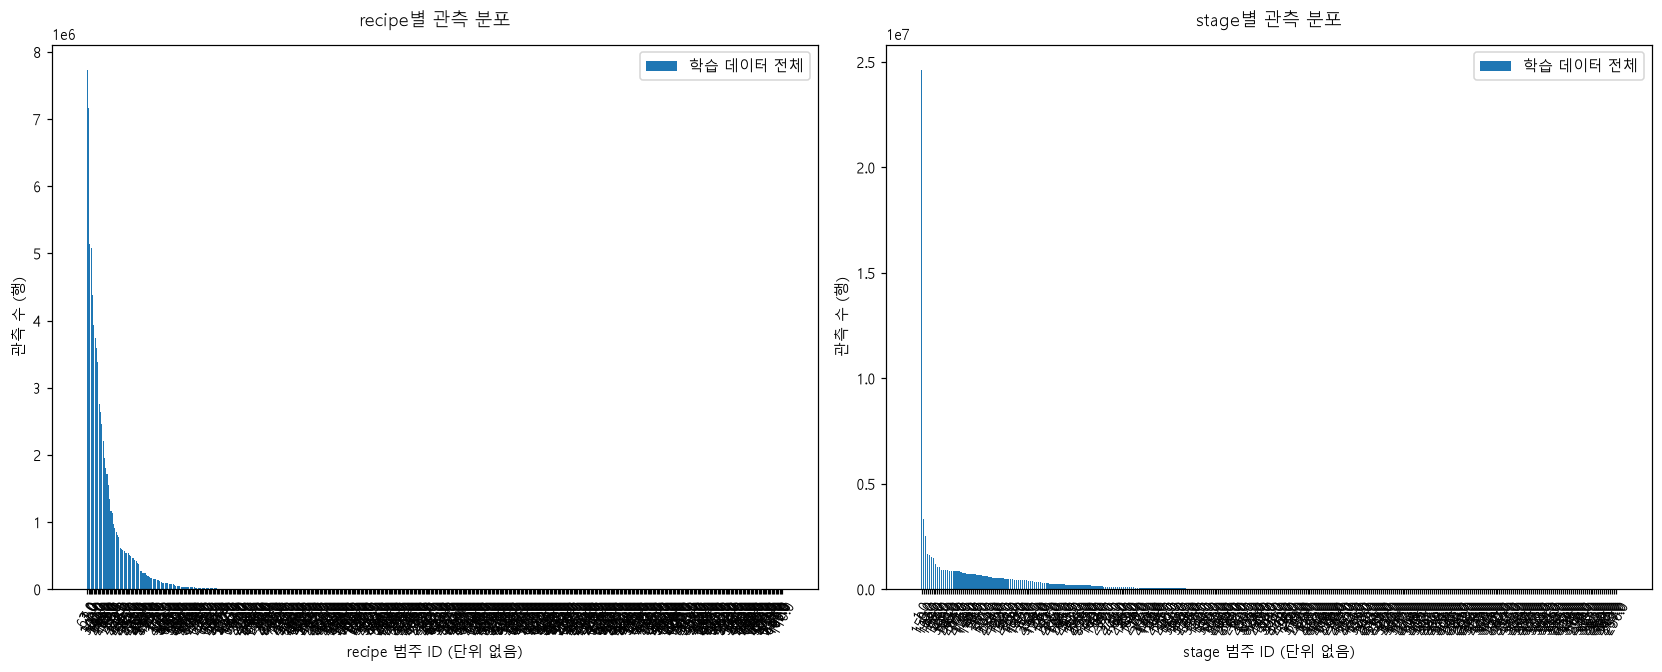

원본 크기·수정 시각 유지: True


공정 범주와 장비에 따른 관측 수 차이가 있으므로 전체 센서 평균만으로 고장 전조를 설명하지 않습니다. 동일 시각 중복과 공백을 먼저 보존·표시하고, 동일 고장 이벤트의 행들이 학습/검증 경계를 넘지 않게 설계해야 합니다.

In [5]:
groups=pd.DataFrame(result["groups"])
distribution=groups.groupby(["split","recipe","stage"],dropna=False)["rows"].sum().reset_index()
display(distribution)
fig,axes=plt.subplots(1,2,figsize=(15,6),layout="constrained")
for ax,col in zip(axes,["recipe","stage"]):
    counts=groups[groups.split=="train"].groupby(col).rows.sum().sort_values(ascending=False)
    ax.bar(counts.index,counts.values,label="학습 데이터 전체")
    ax.set(title=f"{col}별 관측 분포",xlabel=f"{col} 범주 ID (단위 없음)",ylabel="관측 수 (행)")
    ax.tick_params(axis="x",rotation=60);ax.legend()
plots.save(fig,"recipe_stage_distribution")
print("원본 크기·수정 시각 유지:",result["source_metadata_unchanged"])
display(Markdown("공정 범주와 장비에 따른 관측 수 차이가 있으므로 전체 센서 평균만으로 고장 전조를 설명하지 않습니다. 동일 시각 중복과 공백을 먼저 보존·표시하고, 동일 고장 이벤트의 행들이 학습/검증 경계를 넘지 않게 설계해야 합니다."))

## 해석의 근거와 시간 단위 제한

[PHM Society 공식 데이터 설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)을 확인했습니다. 수치 단위는 익명화되어 있고, fault 시각은 정비를 위해 정지한 시점입니다. 실제 이상 시작 시각은 제공되지 않습니다. 문서의 초 표기는 예시이므로 분 단위는 확정하지 않습니다. 뒤의 300·600·1800·3600 원시시간 구간을 **time=초 가정의 5·10·30·60분**으로 병기합니다. TTF와 fault의 일치는 동일 시간 좌표를 검증할 뿐 물리 단위 자체를 증명하지 않습니다.